# Plot a Mork-2 training run

Reads `runs/<timestamp>/metrics.csv` from `mork-train`. The newest run is selected unless `RUN_NAME` is set.

In [11]:
import json
from pathlib import Path

%matplotlib inline
import matplotlib.pyplot as plt
import pandas as pd

RUNS_DIR = Path("../runs")
RUN_NAME = None  # e.g. "20261018_120000"

runs = sorted(p for p in RUNS_DIR.glob("*") if p.is_dir() and (p / "metrics.csv").exists())
print("available runs:", [r.name for r in runs] or "(none)")

if RUN_NAME is not None:
    RUN = RUNS_DIR / RUN_NAME
    assert (RUN / "metrics.csv").exists(), f"no metrics.csv in {RUN}"
elif runs:
    RUN = runs[-1]
else:
    RUN = None

train = val = None
if RUN is None:
    print(f"no runs yet under {RUNS_DIR.resolve()} — start one with mork-train")
else:
    print(f"plotting {RUN.name}")
    cfg_path = RUN / "config.json"
    if cfg_path.exists():
        cfg = json.loads(cfg_path.read_text())
        model = cfg.get("model", {})
        train_cfg = cfg.get("train", {})
        print(
            "config:",
            f"L{model.get('n_layer')} D{model.get('n_embd')} V{model.get('vocab_size')}",
            f"seq {train_cfg.get('seq_len')}",
            f"batch {train_cfg.get('batch_size')}",
            f"tokens/step {train_cfg.get('total_batch_size')}",
            f"max_lr {train_cfg.get('max_lr')}",
            f"max_steps {train_cfg.get('max_steps')}",
        )
    df = pd.read_csv(RUN / "metrics.csv")
    train = df.loc[df["split"] == "train"].copy()
    val = df.loc[df["split"] == "val"].copy()

available runs: ['20261017_190144']
plotting 20261017_190144
config: L12 D768 V16384 seq 512 batch 2 tokens/step 32768 max_lr 0.0008 max_steps 4000


## Loss and learning rate

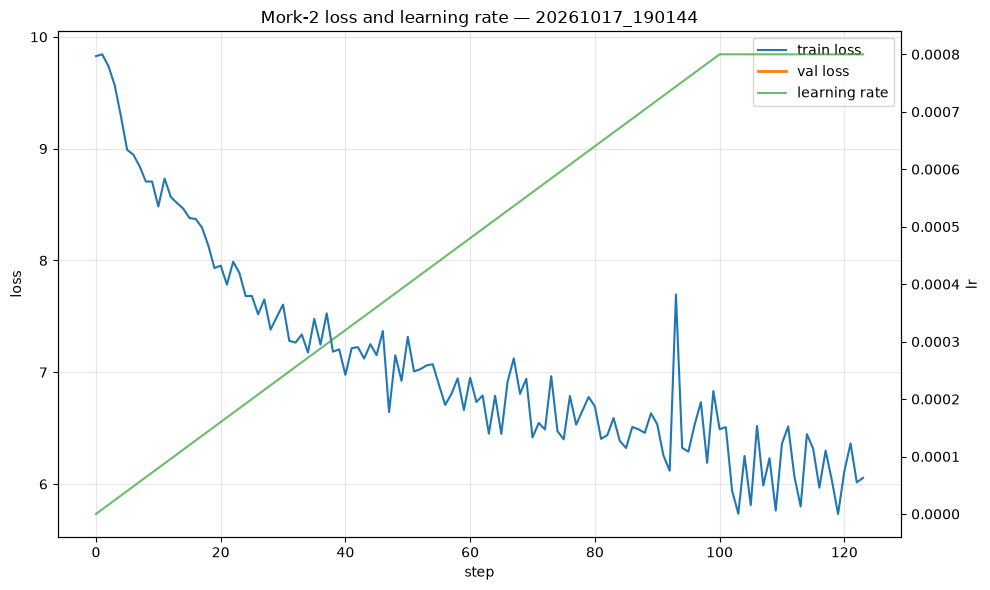

     step      loss      lr  grad_norm  tokens_per_sec    dt_ms
120   119  5.732178  0.0008   1.001460        14219.64  2304.42
121   120  6.112700  0.0008   0.973199        14264.48  2297.17
122   121  6.363246  0.0008   0.901009        14233.78  2302.13
123   122  6.014481  0.0008   1.247917        14289.79  2293.11
124   123  6.054888  0.0008   0.731047        14291.11  2292.89
     step     loss
100    99  6.30703


In [12]:
if train is None:
    print("nothing to plot yet")
else:
    fig, ax_loss = plt.subplots(figsize=(10, 6))
    ax_loss.plot(train["step"], train["loss"], label="train loss", linewidth=1.5)
    if not val.empty:
        ax_loss.plot(val["step"], val["loss"], label="val loss", linewidth=2)
    ax_loss.set_ylabel("loss")
    ax_loss.set_xlabel("step")
    ax_loss.set_title(f"Mork-2 loss and learning rate — {RUN.name}")
    ax_loss.grid(True, alpha=0.3)

    ax_lr = ax_loss.twinx()
    ax_lr.plot(
        train["step"],
        train["lr"],
        label="learning rate",
        color="tab:green",
        linewidth=1.5,
        alpha=0.7,
    )
    ax_lr.set_ylabel("lr")

    lines, labels = ax_loss.get_legend_handles_labels()
    lines2, labels2 = ax_lr.get_legend_handles_labels()
    ax_loss.legend(lines + lines2, labels + labels2, loc="upper right")
    plt.tight_layout()
    plt.show()

    cols = [c for c in ("step", "loss", "lr", "grad_norm", "tokens_per_sec", "dt_ms") if c in train.columns]
    print(train[cols].tail())
    if not val.empty:
        print(val[["step", "loss"]].tail())

## Throughput

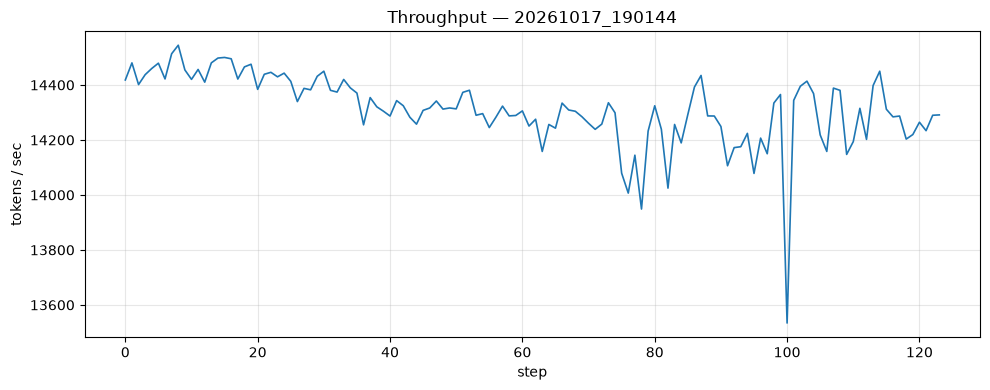

median tokens/sec: 14,314


In [13]:
if train is None:
    print("nothing to plot yet")
elif "tokens_per_sec" not in train.columns:
    print("no throughput column yet")
else:
    speed = train.dropna(subset=["tokens_per_sec"])
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.plot(speed["step"], speed["tokens_per_sec"], linewidth=1.2)
    ax.set(xlabel="step", ylabel="tokens / sec", title=f"Throughput — {RUN.name}")
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()
    print(f"median tokens/sec: {speed['tokens_per_sec'].median():,.0f}")

## Validation improvement

Skips the first few evals, then plots how much validation loss fell since the previous eval.

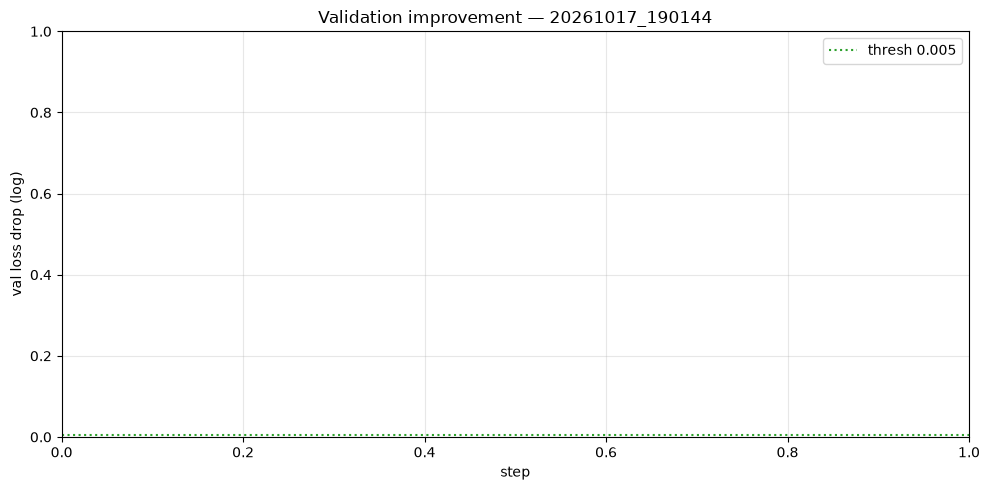

no positive validation drops in this window


In [14]:
SKIP_FIRST = 5
THRESH = 0.005

if val is None or val.empty:
    print("no validation points yet")
else:
    v = val.sort_values("step").assign(improve=lambda d: -d["loss"].diff())
    v = v.dropna(subset=["improve"]).iloc[SKIP_FIRST:]
    falling = v.loc[v["improve"] > 0]

    fig, ax = plt.subplots(figsize=(10, 5))
    if not falling.empty:
        ax.semilogy(falling["step"], falling["improve"], marker="o", label="val loss drop")
    ax.axhline(THRESH, color="tab:green", ls=":", label=f"thresh {THRESH}")
    ax.set(
        xlabel="step",
        ylabel="val loss drop (log)",
        title=f"Validation improvement — {RUN.name}",
    )
    ax.legend()
    ax.grid(True, which="both", alpha=0.3)
    plt.tight_layout()
    plt.show()

    if falling.empty:
        print("no positive validation drops in this window")
    else:
        print(falling[["step", "loss", "improve"]].tail(10).to_string(index=False))